# 1. Project objective

## Feature engineering/ model preparation - Customer Churn Analysis

### Objective
Analyse customer characteristics associated with churn and develop
classification models to identify customers at higher risk of churn.

### Predictive Modelling
The exploratory analysis identified several customer characteristics associated with churn. The next step is to evaluate whether these features can be used to predict customer churn.

### Tools
Python, pandas, matplotlib, seaborn, scikit-learn

# 2. Import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statistics as stat # statistics Library

from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import roc_curve, roc_auc_score

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

# 3. Load data

In [2]:
data = pd.read_csv('../data/cleaned_churn_data.csv')

# check data
data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Churn_binary,tenure_group
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0,0-12 months
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,One year,No,Mailed check,56.95,1889.50,No,0,25-48 months
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,0-12 months
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,0,25-48 months
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,0-12 months


In [3]:
# Remove unnecessary columns
model_data = data.drop(columns = ['customerID', 'Churn_binary','tenure_group'])
model_data.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
# Encode categorical variables -> numerical columns, yes/no
model_encoded = pd.get_dummies(model_data, drop_first = True)
model_encoded.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,Churn_Yes
0,0,1,29.85,29.85,False,True,False,False,True,False,...,False,False,False,False,False,True,False,True,False,False
1,0,34,56.95,1889.50,True,False,False,True,False,False,...,False,False,False,True,False,False,False,False,True,False
2,0,2,53.85,108.15,True,False,False,True,False,False,...,False,False,False,False,False,True,False,False,True,True
3,0,45,42.30,1840.75,True,False,False,False,True,False,...,False,False,False,True,False,False,False,False,False,False
4,0,2,70.70,151.65,False,False,False,True,False,False,...,False,False,False,False,False,True,False,True,False,True


In [5]:
# define y target variable
y = model_encoded['Churn_Yes']
y.head()

0    False
1    False
2     True
3    False
4     True
Name: Churn_Yes, dtype: bool

In [6]:
# define X features
X = model_encoded.drop('Churn_Yes', axis = 1)
X.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,False,True,False,False,True,False,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,True,False,False,True,False,False,...,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,True,False,False,True,False,False,...,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,True,False,False,False,True,False,...,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,False,False,False,True,False,False,...,False,False,False,False,False,False,True,False,True,False


In [7]:
# Train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=42, stratify=y)
# Because churn is imbalanced, stratify=y helps preserve approximately the same churn proportion in the training and test sets.

# 8. Logistic Regression

In [8]:
# model - Logistic Regression
model_lg = LogisticRegression(max_iter = 10000)
model_lg.fit(X_train, y_train)

LogisticRegression(max_iter=10000)

In [9]:
# Prediction
y_pred_lg = model_lg.predict(X_test)

accuracy (LogisticRegression): 0.804
              precision    recall  f1-score   support

       False       0.85      0.89      0.87      1033
        True       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



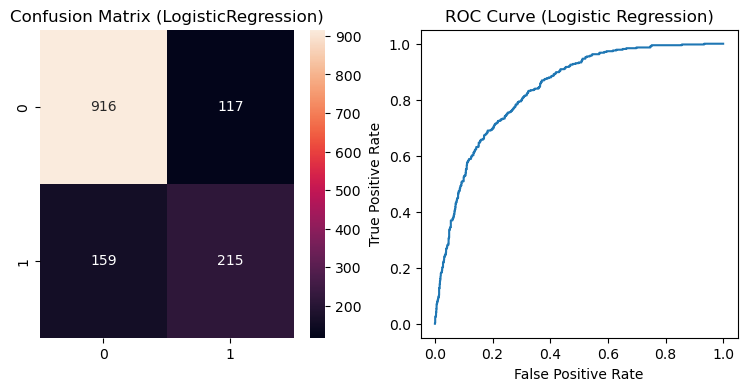

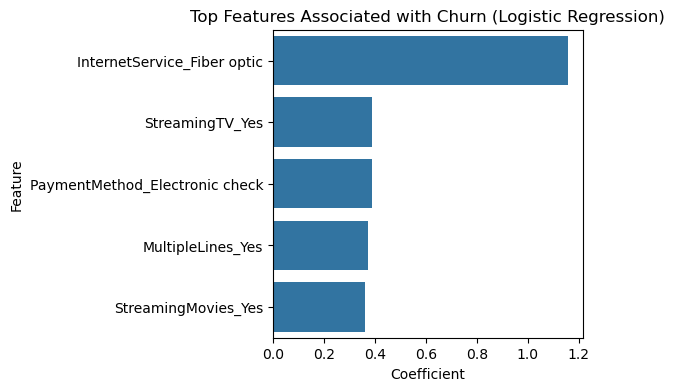

In [10]:
# Evaluate model

# Accuracy
accuracy_lg = accuracy_score(y_test, y_pred_lg)
print('accuracy (LogisticRegression):', round(accuracy_lg, 3))

# Classification report
report_lg = classification_report(y_test, y_pred_lg)
print(report_lg)

# Confusion matrix
cm_lg = confusion_matrix(y_test, y_pred_lg)

plt.figure(figsize=(9,4))
plt.subplot(1,2,1)
sns.heatmap(cm_lg, annot = True, fmt = 'd')
plt.title('Confusion Matrix (LogisticRegression)')
#plt.show()

# ROC Curve
y_prob_lg = model_lg.predict_proba(X_test)[:,1]
fpr_lg, tpr_lg, thresholds_lg = roc_curve(y_test, y_prob_lg)
plt.subplot(1,2,2)
plt.plot(fpr_lg, tpr_lg)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve (Logistic Regression)')
plt.show()

# Feature importance
importance_lg = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model_lg.coef_[0]
})
importance_lg_1 = importance_lg.sort_values(by='Coefficient', ascending=False).head(5)

plt.figure(figsize=(4,4))
sns.barplot(x='Coefficient', y='Feature', data=importance_lg_1.head(5))
plt.title('Top Features Associated with Churn (Logistic Regression)')
plt.show()

In [11]:
# save feature importance for Power BI
importance_lg.to_csv(
    '../results/logistic_regression_feature_importance_1.csv',
    index=False
)

# 9. Random Forest

In [12]:
## Random Forest
model_rf = RandomForestClassifier(random_state=42)
model_rf.fit(X_train, y_train)


RandomForestClassifier(random_state=42)

In [13]:
# Prediction
y_pred_rf = model_rf.predict(X_test)

accuracy (Random Forest): 0.79
              precision    recall  f1-score   support

       False       0.84      0.89      0.86      1033
        True       0.63      0.52      0.57       374

    accuracy                           0.79      1407
   macro avg       0.73      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407



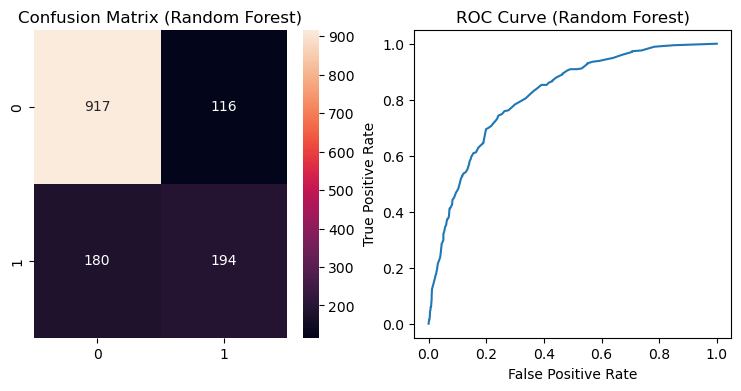

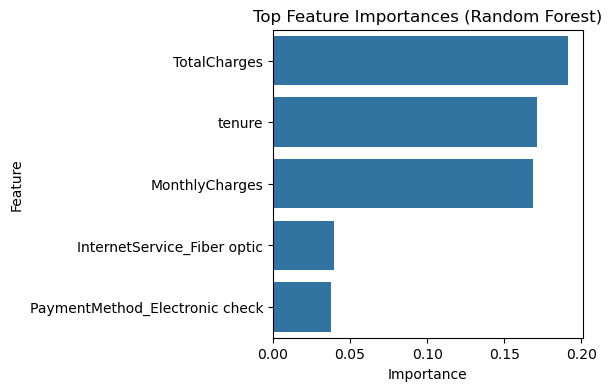

In [14]:
# Evaluate model

# Accuracy
accuracy_rf = accuracy_score(y_test, y_pred_rf)
print('accuracy (Random Forest):', round(accuracy_rf,3))

# Classification report
report_rf = classification_report(y_test, y_pred_rf)
print(report_rf)

# Confusion matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(9,4))
plt.subplot(1,2,1)
sns.heatmap(cm_rf, annot = True, fmt = 'd')
plt.title('Confusion Matrix (Random Forest)')
#plt.show()

# ROC Curve
y_prob_rf = model_rf.predict_proba(X_test)[:,1]
fpr_rf, tpr_rf, thresholds_rf = roc_curve(y_test, y_prob_rf)
plt.subplot(1,2,2)
plt.plot(fpr_rf, tpr_rf)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve (Random Forest)')
plt.show()

# Feature importance
#import pandas as pd
importance_rf = model_rf.feature_importances_
importance_rf_1 = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importance_rf
})
importance_rf_2 = importance_rf_1.sort_values(by='Importance', ascending=False).head(5)

plt.figure(figsize=(4,4))
sns.barplot(x='Importance', y='Feature', data=importance_rf_2.head(5))
plt.title('Top Feature Importances (Random Forest)')
plt.show()

In [15]:
# save importance of random forest
importance_rf_1.to_csv(
    '../results/random_forest_feature_importance_1.csv',
    index=False
)

# 10. Model comparison

In [16]:
# Compare model performance
logistic_metrics = {
    'Model': 'Logistic Regression',
    'Accuracy': accuracy_score(y_test, y_pred_lg),
    'Precision': precision_score(y_test, y_pred_lg),
    'Recall': recall_score(y_test, y_pred_lg),
    'F1': f1_score(y_test, y_pred_lg),
    'ROC_AUC': roc_auc_score(y_test, model_lg.predict_proba(X_test)[:,1])
}

rf_metrics = {
    'Model': 'Random Forest',
    'Accuracy': accuracy_score(y_test, y_pred_rf),
    'Precision': precision_score(y_test, y_pred_rf),
    'Recall': recall_score(y_test, y_pred_rf),
    'F1': f1_score(y_test, y_pred_rf),
    'ROC_AUC': roc_auc_score(y_test, model_rf.predict_proba(X_test)[:,1])
}

metrics_ml = pd.DataFrame([
    logistic_metrics,
    rf_metrics,
])

metrics_ml


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,0.803838,0.647590,0.574866,0.609065,0.836162
1,Random Forest,0.789623,0.625806,0.518717,0.567251,0.816490


## Model Interpretation

The Logistic Regression and Random Forest models were compared 
using accuracy, precision, recall, F1-score and ROC-AUC.

Because the objective is to identify customers at risk of churn, recall is particularly important: 
a false negative represents a customer who actually churns but is not identified by the model.

Model performance should therefore be assessed using multiple metrics
rather than accuracy alone.

In [17]:
# save
metrics_ml.to_csv(
    '../results/model_performance_metrics_1.csv',
    index=False
)

In [18]:
model_data.to_csv('../data/cleaned_churn_model_data.csv', index=False)